# Validación documental de la extracción

Este cuaderno reproduce la selección de la muestra, prepara las fichas de cotejo y
resume los dictámenes registrados. **Funciona de forma independiente** del cuaderno
de resultados y conserva sus salidas para consulta sin volver a ejecutarlo.

**Resultados registrados:** 24 unidades conflicto–mes, 21 conflictos distintos,
439 registros y 426 relaciones mensuales únicas. El cotejo asistido identifica
17 unidades sin discrepancia y 7 con discrepancias. **La ratificación manual de las
24 unidades permanece pendiente.** El programa no decide automáticamente si la
representación de un actor es correcta.

**Uso:** abrir con un núcleo nuevo de Python 3.12 y ejecutar las celdas en orden.
Se reconoce el Excel completo y los PDF de la estructura del repositorio; también
se admite el CSV compartido. Fuera del repositorio se descargan los insumos públicos
de referencia que falten. Los archivos generados se guardan en `salidas_validacion_extraccion/`.

### Fuente y alcance de esta entrega

Se conserva la versión [`b2736d1`](https://github.com/MarSury03/conflictos_mineros_peru_grafos/tree/b2736d1271dd1096d842ae889aa93c89f88d37f4)
de [MarSury03/conflictos_mineros_peru_grafos](https://github.com/MarSury03/conflictos_mineros_peru_grafos).
Su base Excel coincide celda por celda con el CSV utilizado en el cotejo:
21.327 filas y 19 columnas. Las referencias de documentos, parámetros y dictámenes
están incorporadas en este archivo; no se importan programas del otro cuaderno.

Las 39 decisiones sobre pares de casos de la fase 1 corresponden a la vinculación
longitudinal y son distintas de la revisión de actores aquí presentada. Sus porcentajes
describen exclusivamente las 24 unidades de la muestra, sin estimar exactitud global.

## 1. Preparación

Esta celda instala únicamente las versiones requeridas que falten o sean diferentes.
La primera ejecución necesita conexión a internet si hay que instalar bibliotecas.
En Jupyter o Google Colab debe utilizarse un entorno de Python 3.12.

In [1]:
import sys
import subprocess
import importlib
from importlib.metadata import version, PackageNotFoundError

if sys.version_info < (3, 12):
    raise RuntimeError("Utilice Python 3.12 o posterior; la ejecución de referencia usó Python 3.12.")

VERSIONES_REQUERIDAS = {'pandas': '3.0.1', 'pypdf': '6.21.4', 'pdfplumber': '0.11.9', 'matplotlib': '3.11.2', 'openpyxl': '3.1.5'}
instalar = []
for paquete, requerida in VERSIONES_REQUERIDAS.items():
    try:
        instalada = version(paquete)
    except PackageNotFoundError:
        instalada = None
    if instalada != requerida:
        instalar.append(f"{paquete}=={requerida}")
if instalar:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *instalar])
    importlib.invalidate_caches()
print("Bibliotecas disponibles en las versiones de referencia.")

Bibliotecas disponibles en las versiones de referencia.


In [2]:
import hashlib
import io
import json
import platform
import urllib.parse
import urllib.request
from collections import Counter, defaultdict
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

import difflib
import html
import random
import re
import unicodedata
from datetime import date
import pdfplumber
from pypdf import PdfReader

CONFORME = "Sin discrepancia identificada en el alcance revisado"
DISCREPANCIA = "Con discrepancia"
DICTAMENES = {CONFORME, DISCREPANCIA}

pd.set_option("display.max_columns", 10)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.max_rows", 30)
plt.rcParams.update({
    "figure.figsize": (9, 4), "figure.dpi": 130, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 13,
})
CLAVE = ["periodo_reporte", "id_caso", "Id_actor"]
entorno = {"Python": platform.python_version(),
           **{p: version(p) for p in VERSIONES_REQUERIDAS}}
display(pd.Series(entorno, name="Versión ejecutada").to_frame())

,Versión ejecutada
Python,3.12.14
pandas,3.0.1
pypdf,6.21.4
pdfplumber,0.11.9
matplotlib,3.11.2
openpyxl,3.1.5


### Parámetros y alcance

Los seis meses se eligieron de forma dirigida para cubrir años y formatos documentales distintos.
Dentro de cada mes se seleccionan cuatro casos al azar, sin reemplazo. La semilla **20261111**
corresponde a ese muestreo; se usa una sola instancia aleatoria, sin reiniciarla entre meses.


El cotejo examina los bloques de actores y sus continuaciones: identidad del caso, nombres
originales y normalizados, delimitación de entidades, roles e identificadores cuando existe
evidencia comparable. Una mención en la narración de hechos, fuera de esos bloques, no se
considera automáticamente una omisión. La selección solo incluye casos presentes en la base;
sus resultados no estiman exactitud global, exhaustividad, precisión, recobrado ni F1 del filtro minero.

Según lo informado por el autor, la extracción original no utilizó un modelo de IA. Los
dictámenes que se conservan aquí proceden del cotejo documental asistido realizado durante
la revisión. **Este cuaderno no ejecuta ningún modelo de IA.**

In [3]:
# None permite localizar la base del repositorio; puede indicar aquí un CSV o XLSX.
RUTA_DATOS = None
RAIZ_REPO = next((p for p in [Path.cwd(), *list(Path.cwd().parents)[:3]]
                  if (p / "fase1_base_longitudinal").is_dir()
                  and (p / "fases2_5_analisis_grafos").is_dir()), Path.cwd())
carpeta_pdf_repo = RAIZ_REPO / "fase1_base_longitudinal/datos/reportes_pdf"
RUTA_REPORTES = carpeta_pdf_repo if carpeta_pdf_repo.is_dir() else Path("reportes_validacion")
RUTA_SALIDAS = Path("salidas_validacion_extraccion")
DESCARGAR_BASE_SI_FALTA = True
DESCARGAR_REPORTES_FALTANTES = True
REPOSITORIO = "MarSury03/conflictos_mineros_peru_grafos"
COMMIT_REFERENCIA = "b2736d1271dd1096d842ae889aa93c89f88d37f4"
RUTA_BASE_REPO = "fase1_base_longitudinal/resultados/FASE1_MINERIA_CON_IDS_ACTORES_Y_CASOS.xlsx"
URL_BASE_REPO = f"https://raw.githubusercontent.com/{REPOSITORIO}/{COMMIT_REFERENCIA}/{RUTA_BASE_REPO}"
SHA256_EXCEL_REPO = "0dfea7e573735e4edf07d7cb0c3ac2870ceec44eb5dbf29b0f8bf5a4e4dcc218"

# Opcional: ruta a la plantilla completada por un revisor. None conserva la revisión pendiente.
RUTA_REVISION_MANUAL = None

SEMILLA_MUESTRA = 20261111
PERIODOS_MUESTRA = ["2021-01", "2022-07", "2023-06", "2024-09", "2024-10", "2025-12"]
CASOS_POR_PERIODO = 4
PAGINAS_CONSECUTIVAS = 2
CARACTERES_DESCRIPCION = 110
RECORTE = {"izquierda": 25, "superior": 65, "fraccion_derecha": 0.5, "margen_inferior": 45}

if RUTA_DATOS is None:
    nombre_csv = "FASE1_MINERIA_CON_IDS_ACTORES_Y_CASOS.csv"
    candidatos = [Path(nombre_csv), RAIZ_REPO / RUTA_BASE_REPO,
                  Path("datos") / nombre_csv, Path("data") / nombre_csv,
                  Path("..") / nombre_csv]
    RUTA_DATOS = next((p for p in candidatos if p.is_file()), None)
    if RUTA_DATOS is None:
        RUTA_DATOS = Path("insumos_validacion") / Path(RUTA_BASE_REPO).name
        if not RUTA_DATOS.is_file():
            if not DESCARGAR_BASE_SI_FALTA:
                raise FileNotFoundError("Indique RUTA_DATOS o habilite la descarga de la base de referencia.")
            with urllib.request.urlopen(URL_BASE_REPO, timeout=60) as respuesta:
                contenido = respuesta.read()
            if hashlib.sha256(contenido).hexdigest() != SHA256_EXCEL_REPO:
                raise ValueError("La descarga de la base no coincide con la versión revisada.")
            RUTA_DATOS.parent.mkdir(parents=True, exist_ok=True)
            RUTA_DATOS.write_bytes(contenido)
RUTA_DATOS = Path(RUTA_DATOS)
if not RUTA_DATOS.is_file():
    raise FileNotFoundError(f"No se encuentra la base indicada: {RUTA_DATOS}")
RUTA_SALIDAS.mkdir(parents=True, exist_ok=True)

def guardar_json(nombre, contenido):
    (RUTA_SALIDAS / nombre).write_text(
        json.dumps(contenido, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

def huella_archivo(ruta):
    return hashlib.sha256(Path(ruta).read_bytes()).hexdigest()

def huella_contenido(tabla):
    # Tolera cambios de BOM y de finales de línea que puede introducir Git.
    # Conserva orden, columnas y todos los valores; no permite cambiar registros.
    contenido = {
        "columnas": list(tabla.columns),
        "registros": [[v.replace("\r\n", "\n").replace("\r", "\n") for v in fila]
                      for fila in tabla.itertuples(index=False, name=None)],
    }
    serializado = json.dumps(contenido, ensure_ascii=False, separators=(",", ":"))
    return hashlib.sha256(serializado.encode("utf-8")).hexdigest()

## 2. Identidad y recuentos de la base

Las relaciones mensuales se identifican con la clave `(periodo_reporte, id_caso, Id_actor)`.
Varias filas con esa clave pueden conservar apariciones o roles distintos de un actor.
Se cuentan una sola vez al construir cada red. Los nodos se identifican por sus códigos;
el cuaderno no fusiona actores por semejanza de sus nombres ni aplica correcciones a la base.

La huella de contenido comprueba que los dictámenes incorporados correspondan exactamente
a esta versión de los registros. Una modificación de los datos exige una nueva revisión.
El campo `sha256_base` del registro de dictámenes conserva la huella del CSV original;
la equivalencia del contenido permite utilizar también su copia Excel.

In [4]:
SHA256_ARCHIVO_REFERENCIA = '1aaf6248848669126a5d8fe58381575d4105af19c28d84a61fd61a5ca503d126'
SHA256_CONTENIDO_REFERENCIA = '4610ae71308f126e618c28a65328ee7afac9b150f02dc4e12b950c88035c3ed9'
if RUTA_DATOS.suffix.lower() == ".csv":
    datos = pd.read_csv(RUTA_DATOS, dtype=str, keep_default_na=False, encoding="utf-8-sig")
elif RUTA_DATOS.suffix.lower() == ".xlsx":
    datos = pd.read_excel(RUTA_DATOS, sheet_name="Base final fase 1", dtype=str, keep_default_na=False)
else:
    raise ValueError("Se admite el CSV completo o el Excel 'Base final fase 1'.")
requeridas = set(CLAVE + ["reporte", "pagina_pdf", "caso", "ubicacion", "tipo_actor",
                         "actor", "Actor_normalizado", "bloque_actores_original"])
if requeridas - set(datos.columns):
    raise ValueError(f"Faltan columnas: {sorted(requeridas - set(datos.columns))}")
if datos[CLAVE].apply(lambda c: c.str.strip().eq("").any()).any():
    raise ValueError("Hay valores vacíos en la clave de la relación mensual.")

sha256_base = huella_archivo(RUTA_DATOS)
sha256_contenido = huella_contenido(datos)
if sha256_contenido != SHA256_CONTENIDO_REFERENCIA:
    raise ValueError("La base tiene otro contenido. Los dictámenes incorporados no se pueden trasladar a ella.")
if RUTA_DATOS.suffix.lower() == ".xlsx":
    print("La base Excel coincide celda por celda con el contenido del CSV revisado.")
elif sha256_base != SHA256_ARCHIVO_REFERENCIA:
    print("Cambió la codificación o el formato de líneas; el contenido tabular coincide con la referencia.")

relaciones = datos.drop_duplicates(CLAVE).copy()
perfil = {
    "Registros documentales": len(datos),
    "Duplicados exactos de fila": int(datos.duplicated().sum()),
    "Relaciones mensuales únicas": len(relaciones),
    "Ocurrencias adicionales de la clave mensual": len(datos) - len(relaciones),
    "Unidades conflicto–mes": len(datos.drop_duplicates(CLAVE[:2])),
    "Identificadores de actor": int(datos.Id_actor.nunique()),
    "Identificadores de conflicto": int(datos.id_caso.nunique()),
    "Meses": int(datos.periodo_reporte.nunique()),
}
display(pd.Series(perfil, name="Recuento").to_frame())
print("Intervalo:", datos.periodo_reporte.min(), "a", datos.periodo_reporte.max())
print("Huella SHA-256 del contenido:", sha256_contenido)

La base Excel coincide celda por celda con el contenido del CSV revisado.


,Recuento
Registros documentales,21327
Duplicados exactos de fila,0
Relaciones mensuales únicas,20913
Ocurrencias adicionales de la clave mensual,414
Unidades conflicto–mes,1423
Identificadores de actor,802
Identificadores de conflicto,146
Meses,60


Intervalo: 2021-01 a 2025-12
Huella SHA-256 del contenido: 4610ae71308f126e618c28a65328ee7afac9b150f02dc4e12b950c88035c3ed9


## 3. Reproducción de la muestra documental

La unidad seleccionada es un conflicto en un mes. Al seleccionarla se incluyen todas sus
filas de actores, también las que proceden de páginas de continuación. Los identificadores
elegibles se ordenan antes del sorteo para que el orden de las filas no cambie la selección.

In [5]:
rng = random.Random(SEMILLA_MUESTRA)
muestra = []
elegibles = {}
# fila_csv es el ordinal del registro contando la cabecera; no una línea física del CSV multilínea.
datos_con_fila = datos.copy()
datos_con_fila.insert(0, "fila_csv", datos.index + 2)
campos_actores = ["fila_csv", "tipo_actor", "actor", "Id_actor",
                  "Actor_normalizado", "bloque_actores_original"]
for periodo in PERIODOS_MUESTRA:
    grupo = datos_con_fila[datos_con_fila.periodo_reporte.eq(periodo)]
    ids = sorted(grupo.id_caso.unique())
    if len(ids) < CASOS_POR_PERIODO:
        raise ValueError(f"No hay suficientes casos en {periodo}.")
    elegibles[periodo] = len(ids)
    for id_caso in sorted(rng.sample(ids, CASOS_POR_PERIODO)):
        filas = grupo[grupo.id_caso.eq(id_caso)]
        if filas.reporte.nunique() != 1:
            raise ValueError(f"{periodo}/{id_caso} tiene varios reportes.")
        muestra.append({
            "unidad": f"M{len(muestra) + 1:02d}", "periodo": periodo, "id_caso": id_caso,
            "reporte": filas.iloc[0].reporte,
            "paginas": sorted(filas.pagina_pdf.unique(), key=int),
            "descripcion": filas.iloc[0].caso, "ubicacion": filas.iloc[0].ubicacion,
            "filas": len(filas), "relaciones_unicas": int(filas.Id_actor.nunique()),
            "actores": filas[campos_actores].to_dict("records"),
        })
tabla_muestra = pd.DataFrame([
    {k: v for k, v in u.items() if k not in {"actores", "descripcion", "ubicacion"}}
    for u in muestra
])
tabla_muestra["paginas"] = tabla_muestra.paginas.map(lambda ps: ";".join(ps))
tabla_muestra["ocurrencias_adicionales"] = tabla_muestra.filas - tabla_muestra.relaciones_unicas
display(tabla_muestra)
print(f"{len(muestra)} unidades; {tabla_muestra.id_caso.nunique()} conflictos distintos; "
      f"{tabla_muestra.filas.sum()} filas; {tabla_muestra.relaciones_unicas.sum()} relaciones únicas.")
tabla_muestra.to_csv(RUTA_SALIDAS / "muestra_seleccionada.csv", index=False, encoding="utf-8-sig")
guardar_json("muestra_seleccionada.json", muestra)

,unidad,periodo,id_caso,reporte,paginas,filas,relaciones_unicas,ocurrencias_adicionales
0,M01,2021-01,CAS-0006,203,35,28,28,0
1,M02,2021-01,CAS-0009,203,41,26,26,0
2,M03,2021-01,CAS-0012,203,44,28,25,3
3,M04,2021-01,CAS-0015,203,48,40,40,0
4,M05,2022-07,CAS-0028,221,40,14,14,0
5,M06,2022-07,CAS-0049,221,56,20,20,0
6,M07,2022-07,CAS-0065,221,48,20,19,1
7,M08,2022-07,CAS-0089,221,66,15,14,1
8,M09,2023-06,CAS-0005,232,37,40,40,0
9,M10,2023-06,CAS-0006,232,41,28,28,0


24 unidades; 21 conflictos distintos; 439 filas; 426 relaciones únicas.


### Comprobación de la selección registrada

Esta comprobación reproduce qué unidades y cuántos registros se seleccionaron.
No comprueba la veracidad de los dictámenes documentales.

In [6]:
MUESTRA_REFERENCIA = json.loads(r'''[
  {
    "unidad": "M01",
    "periodo": "2021-01",
    "id_caso": "CAS-0006",
    "reporte": "203",
    "filas": "28",
    "relaciones": "28"
  },
  {
    "unidad": "M02",
    "periodo": "2021-01",
    "id_caso": "CAS-0009",
    "reporte": "203",
    "filas": "26",
    "relaciones": "26"
  },
  {
    "unidad": "M03",
    "periodo": "2021-01",
    "id_caso": "CAS-0012",
    "reporte": "203",
    "filas": "28",
    "relaciones": "25"
  },
  {
    "unidad": "M04",
    "periodo": "2021-01",
    "id_caso": "CAS-0015",
    "reporte": "203",
    "filas": "40",
    "relaciones": "40"
  },
  {
    "unidad": "M05",
    "periodo": "2022-07",
    "id_caso": "CAS-0028",
    "reporte": "221",
    "filas": "14",
    "relaciones": "14"
  },
  {
    "unidad": "M06",
    "periodo": "2022-07",
    "id_caso": "CAS-0049",
    "reporte": "221",
    "filas": "20",
    "relaciones": "20"
  },
  {
    "unidad": "M07",
    "periodo": "2022-07",
    "id_caso": "CAS-0065",
    "reporte": "221",
    "filas": "20",
    "relaciones": "19"
  },
  {
    "unidad": "M08",
    "periodo": "2022-07",
    "id_caso": "CAS-0089",
    "reporte": "221",
    "filas": "15",
    "relaciones": "14"
  },
  {
    "unidad": "M09",
    "periodo": "2023-06",
    "id_caso": "CAS-0005",
    "reporte": "232",
    "filas": "40",
    "relaciones": "40"
  },
  {
    "unidad": "M10",
    "periodo": "2023-06",
    "id_caso": "CAS-0006",
    "reporte": "232",
    "filas": "28",
    "relaciones": "28"
  },
  {
    "unidad": "M11",
    "periodo": "2023-06",
    "id_caso": "CAS-0055",
    "reporte": "232",
    "filas": "15",
    "relaciones": "15"
  },
  {
    "unidad": "M12",
    "periodo": "2023-06",
    "id_caso": "CAS-0103",
    "reporte": "232",
    "filas": "8",
    "relaciones": "8"
  },
  {
    "unidad": "M13",
    "periodo": "2024-09",
    "id_caso": "CAS-0044",
    "reporte": "247",
    "filas": "14",
    "relaciones": "14"
  },
  {
    "unidad": "M14",
    "periodo": "2024-09",
    "id_caso": "CAS-0068",
    "reporte": "247",
    "filas": "8",
    "relaciones": "8"
  },
  {
    "unidad": "M15",
    "periodo": "2024-09",
    "id_caso": "CAS-0112",
    "reporte": "247",
    "filas": "7",
    "relaciones": "7"
  },
  {
    "unidad": "M16",
    "periodo": "2024-09",
    "id_caso": "CAS-0128",
    "reporte": "247",
    "filas": "6",
    "relaciones": "6"
  },
  {
    "unidad": "M17",
    "periodo": "2024-10",
    "id_caso": "CAS-0012",
    "reporte": "248",
    "filas": "28",
    "relaciones": "25"
  },
  {
    "unidad": "M18",
    "periodo": "2024-10",
    "id_caso": "CAS-0051",
    "reporte": "248",
    "filas": "21",
    "relaciones": "21"
  },
  {
    "unidad": "M19",
    "periodo": "2024-10",
    "id_caso": "CAS-0069",
    "reporte": "248",
    "filas": "11",
    "relaciones": "11"
  },
  {
    "unidad": "M20",
    "periodo": "2024-10",
    "id_caso": "CAS-0125",
    "reporte": "248",
    "filas": "22",
    "relaciones": "17"
  },
  {
    "unidad": "M21",
    "periodo": "2025-12",
    "id_caso": "CAS-0055",
    "reporte": "262",
    "filas": "15",
    "relaciones": "15"
  },
  {
    "unidad": "M22",
    "periodo": "2025-12",
    "id_caso": "CAS-0090",
    "reporte": "262",
    "filas": "9",
    "relaciones": "9"
  },
  {
    "unidad": "M23",
    "periodo": "2025-12",
    "id_caso": "CAS-0134",
    "reporte": "262",
    "filas": "11",
    "relaciones": "11"
  },
  {
    "unidad": "M24",
    "periodo": "2025-12",
    "id_caso": "CAS-0139",
    "reporte": "262",
    "filas": "5",
    "relaciones": "5"
  }
]''')

for actual, esperada in zip(muestra, MUESTRA_REFERENCIA, strict=True):
    for campo, valor in esperada.items():
        nombre = "relaciones_unicas" if campo == "relaciones" else campo
        if str(actual[nombre]) != valor:
            raise ValueError(f"No se reproduce {actual['unidad']}: {campo}.")
print("Las 24 unidades y sus recuentos coinciden con la selección registrada.")

Las 24 unidades y sus recuentos coinciden con la selección registrada.


### Reportes originales y control de versiones

Se conserva para cada documento su enlace oficial, número de páginas y huella SHA-256.
Si falta un reporte se descarga; si su contenido difiere de la versión revisada se detiene
el procedimiento para evitar cotejar documentos distintos sin advertirlo.

In [7]:
CATALOGO_REPORTES = json.loads(r'''[
  {
    "reporte": "203",
    "periodo": "2021-01",
    "url": "https://www.defensoria.gob.pe/wp-content/uploads/2021/02/Reporte-Mensual-de-Conflictos-Sociales-N°-203-enero-2021.pdf",
    "paginas": 119,
    "bytes": 2441119,
    "sha256": "f0077c7b3f24405ee1c3de2e03353f93c77ca8ec4a0c7bcbb4a11e951a9632b9",
    "archivo_repositorio": "RCS_203_2021_01_enero.pdf"
  },
  {
    "reporte": "221",
    "periodo": "2022-07",
    "url": "https://www.defensoria.gob.pe/wp-content/uploads/2022/08/Reporte-Mensual-de-Conflictos-Sociales-n.°-221-julio-2022.pdf",
    "paginas": 157,
    "bytes": 3978282,
    "sha256": "d2f2c96370255aa439a52e47d9ed14ab90a34d59256ca5ec9bdaea1a83ad9798",
    "archivo_repositorio": "RCS_221_2022_07_julio.pdf"
  },
  {
    "reporte": "232",
    "periodo": "2023-06",
    "url": "https://www.defensoria.gob.pe/wp-content/uploads/2023/07/Reporte-Mensual-de-Conflictos-Sociales-N°-232-Junio-2023.pdf",
    "paginas": 148,
    "bytes": 3772067,
    "sha256": "8df8d44708298f70d6c7ed3f6b4901ec761dfb1422b147eae87041ecf425fbcb",
    "archivo_repositorio": "RCS_232_2023_06_junio.pdf"
  },
  {
    "reporte": "247",
    "periodo": "2024-09",
    "url": "https://www.defensoria.gob.pe/wp-content/uploads/2024/10/3.pdf",
    "paginas": 150,
    "bytes": 2705341,
    "sha256": "472a87f84117c71d5140c8ffb0aace72b1e4ffd50fa5a881fb2986f80ef53ece",
    "archivo_repositorio": "RCS_247_2024_09_septiembre.pdf"
  },
  {
    "reporte": "248",
    "periodo": "2024-10",
    "url": "https://www.defensoria.gob.pe/wp-content/uploads/2024/11/Reporte-Mensual-de-Conflictos-Sociales-N°-248-Octubre_2024.pdf",
    "paginas": 107,
    "bytes": 2586549,
    "sha256": "5a822369d0adf813a39749bd406e2506c7be7688389c5af53fe4f4900fef6f92",
    "archivo_repositorio": "RCS_248_2024_10_octubre.pdf"
  },
  {
    "reporte": "262",
    "periodo": "2025-12",
    "url": "https://www.defensoria.gob.pe/wp-content/uploads/2026/01/Reporte-de-conflictos-sociales-n.º-262-–-diciembre-2025.pdf",
    "paginas": 120,
    "bytes": 2620335,
    "sha256": "09e03dbba9d315f888f6d7fc71344bc1547e6b5cc8ffabe666d3ad5d691333bf",
    "archivo_repositorio": "RCS_262_2025_12_diciembre.pdf"
  }
]''')
catalogo = {r['reporte']: r for r in CATALOGO_REPORTES}

In [8]:
manifiesto_fuentes = []
lectores = {}
rutas_reportes = {}
for numero in sorted({u["reporte"] for u in muestra}, key=int):
    fuente = catalogo[numero]
    candidatos = [RUTA_REPORTES / fuente["archivo_repositorio"], RUTA_REPORTES / f"RCS_{numero}.pdf"]
    ruta = next((p for p in candidatos if p.exists()), candidatos[0])
    if not ruta.exists():
        if not DESCARGAR_REPORTES_FALTANTES:
            raise FileNotFoundError(f"Falta {ruta}. Fuente: {fuente['url']}")
        url = urllib.parse.quote(fuente["url"], safe=":/?=&%")
        solicitud = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(solicitud, timeout=60) as respuesta:
            contenido = respuesta.read()
        if not contenido.lstrip().startswith(b"%PDF"):
            raise ValueError(f"La fuente {numero} no devolvió un PDF.")
        if hashlib.sha256(contenido).hexdigest() != fuente["sha256"]:
            raise ValueError(f"El reporte {numero} cambió de versión; no se guardó.")
        ruta.parent.mkdir(parents=True, exist_ok=True)
        ruta.write_bytes(contenido)
    if huella_archivo(ruta) != fuente["sha256"]:
        raise ValueError(f"El reporte local {numero} no coincide con la versión revisada.")
    lector = PdfReader(ruta)
    if len(lector.pages) != fuente["paginas"]:
        raise ValueError(f"Número de páginas diferente en el reporte {numero}.")
    lectores[numero] = lector
    rutas_reportes[numero] = ruta
    manifiesto_fuentes.append({**fuente, "estado": "Versión comprobada"})
display(pd.DataFrame(manifiesto_fuentes)[["reporte", "periodo", "paginas", "estado"]])
guardar_json("fuentes_documentales.json", manifiesto_fuentes)

,reporte,periodo,paginas,estado
0,203,2021-01,119,Versión comprobada
1,221,2022-07,157,Versión comprobada
2,232,2023-06,148,Versión comprobada
3,247,2024-09,150,Versión comprobada
4,248,2024-10,107,Versión comprobada
5,262,2025-12,120,Versión comprobada


### Fichas para el cotejo

Para cada unidad se presenta la descripción, los nombres y códigos registrados y el bloque
candidato del documento original. Se consulta la página inicial y su continuación.
La semejanza textual ayuda a localizar el caso: **no mide exactitud ni decide si un actor está bien extraído**.
La ficha incluye también el texto completo de esas páginas y enlaces a los originales para
comprobar visualmente el caso, los roles y la separación de columnas.

In [9]:
def normalizar_localizacion(texto):
    simple = unicodedata.normalize("NFKD", texto.lower()).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9 ]", "", simple)

def localizar_bloque(unidad, documento, lector):
    inicio = int(unidad["paginas"][0])
    paginas = list(range(inicio, min(inicio + PAGINAS_CONSECUTIVAS, len(documento.pages) + 1)))
    textos, contexto = [], []
    for numero in paginas:
        pagina = documento.pages[numero - 1]
        caja = (RECORTE["izquierda"], RECORTE["superior"],
                pagina.width * RECORTE["fraccion_derecha"],
                pagina.height - RECORTE["margen_inferior"])
        textos.append(pagina.crop(caja).extract_text() or "")
        contexto.append({"pagina_pdf": numero, "texto": lector.pages[numero - 1].extract_text() or ""})
    candidatos = re.split(r"(?=Tipo\s*:)", "\n".join(textos))
    def puntuacion(texto):
        segmento = texto[texto.find("Caso:") + 5:]
        return difflib.SequenceMatcher(
            None, normalizar_localizacion(segmento)[:CARACTERES_DESCRIPCION],
            normalizar_localizacion(unidad["descripcion"])[:CARACTERES_DESCRIPCION]).ratio()
    candidato = max(candidatos, key=puntuacion)
    return {**unidad, "fuente_bloque": candidato, "paginas_consultadas": paginas,
            "similitud_localizacion": puntuacion(candidato), "paginas_completas": contexto}

fichas = []
for numero in sorted(lectores, key=int):
    with pdfplumber.open(rutas_reportes[numero]) as documento:
        for unidad in muestra:
            if unidad["reporte"] == numero:
                fichas.append(localizar_bloque(unidad, documento, lectores[numero]))
fichas.sort(key=lambda f: f["unidad"])
guardar_json("fichas_fuente.json", fichas)
print(f"{len(fichas)} fichas preparadas. La revisión documental decide su correspondencia.")

24 fichas preparadas. La revisión documental decide su correspondencia.


In [10]:
def ficha_html(ficha):
    escape = html.escape
    numero = ficha["reporte"]
    enlace = catalogo[numero]["url"] + f"#page={ficha['paginas_consultadas'][0]}"
    tabla = pd.DataFrame(ficha["actores"])[
        ["fila_csv", "tipo_actor", "actor", "Actor_normalizado", "Id_actor"]]
    tabla = tabla.rename(columns={"fila_csv": "Registro", "tipo_actor": "Rol",
                "actor": "Nombre extraído", "Actor_normalizado": "Nombre normalizado", "Id_actor": "ID"})
    contexto = "".join(
        f"<h4>Página PDF {p['pagina_pdf']}</h4><pre>{escape(p['texto'])}</pre>"
        for p in ficha["paginas_completas"])
    return (
        f"<section id='{ficha['unidad']}'><h2>{ficha['unidad']} · {ficha['periodo']} · {ficha['id_caso']}</h2>"
        f"<p><a href='{escape(enlace, quote=True)}'>Abrir reporte {numero} en la página del caso</a></p>"
        f"<h3>Descripción registrada</h3><p>{escape(ficha['descripcion'])}</p>"
        f"<h3>Actores registrados</h3>{tabla.to_html(index=False, escape=True)}"
        f"<h3>Bloque original candidato</h3><pre>{escape(ficha['fuente_bloque'])}</pre>"
        "<p>La semejanza se utiliza para localizar el caso, no para asignar un dictamen.</p>"
        f"<details><summary>Contexto: páginas completas</summary>{contexto}</details></section>")

estilo = '''<style>body{max-width:1100px;margin:30px auto;font:16px Arial;line-height:1.5;padding:0 24px}
table{border-collapse:collapse;width:100%;font-size:14px}th,td{border:1px solid #ccd4da;padding:7px;text-align:left}
pre{white-space:pre-wrap;background:#f3f6f8;padding:16px}section{padding:16px 0;border-bottom:2px solid #dce3e8}
a{color:#175b88}summary{cursor:pointer}</style>'''
cuerpo = "".join(ficha_html(f) for f in fichas)
ruta_fichas = RUTA_SALIDAS / "fichas_para_revision.html"
ruta_fichas.write_text("<!doctype html><html lang='es'><meta charset='utf-8'>" + estilo +
    "<title>Fichas de cotejo documental</title><h1>Fichas para revisión manual</h1>" + cuerpo + "</html>", encoding="utf-8")
display(Markdown(f"**Se generaron las 24 fichas:** [{ruta_fichas.name}]({ruta_fichas.as_posix()})."))
display(pd.DataFrame([{
    "Unidad": f["unidad"], "Reporte": f["reporte"],
    "Páginas consultadas": ";".join(map(str, f["paginas_consultadas"])),
    "Semejanza para localización": round(f["similitud_localizacion"], 3),
} for f in fichas]))

**Se generaron las 24 fichas:** [fichas_para_revision.html](salidas_validacion_extraccion/fichas_para_revision.html).

,Unidad,Reporte,Páginas consultadas,Semejanza para localización
0,M01,203,35;36,0.982
1,M02,203,41;42,0.982
2,M03,203,44;45,0.982
3,M04,203,48;49,0.991
4,M05,221,40;41,0.991
5,M06,221,56;57,0.991
6,M07,221,48;49,0.982
7,M08,221,66;67,0.973
8,M09,232,37;38,0.991
9,M10,232,41;42,0.991


## 4. Dictámenes registrados y ratificación manual

La siguiente celda incorpora los **24 dictámenes del cotejo asistido**, incluidas sus evidencias,
categorías y explicaciones de las repeticiones. Se trata de un insumo documental trazable,
no de etiquetas inferidas por el programa. Los porcentajes posteriores se calculan contando
estos dictámenes. Una fila sin dictamen permanece pendiente y no se considera correcta.

Para ratificar manualmente la revisión, complete `plantilla_revision_manual.csv`, que se genera
en la carpeta de salidas. Registre `dictamen_manual`, `evidencia_manual`, `revisor_manual`,
`fecha_revision_manual` (AAAA-MM-DD) y `ratificacion_manual` (`Ratificado`). Después indique
su ruta en `RUTA_REVISION_MANUAL` y vuelva a ejecutar. Puede corregir el juicio previo;
el resumen manual se calcula por separado. La plantilla existente no se sobrescribe.

In [11]:
REGISTRO_ASISTIDO_CSV = r'''unidad,periodo,id_caso,referencia,reporte,sha256_base,filas,relaciones_unicas,ocurrencias_adicionales,paginas_evidencia,clasificacion_minera,dictamen_reverificado,tipo_revision,categorias,evidencia_reverificada,roles,explicacion_repeticiones,adicionales_respaldadas_fuente,adicionales_por_fragmentacion,dictamen_manual,evidencia_manual,revisor_manual,fecha_revision_manual,ratificacion_manual,fuente_url
M01,2021-01,CAS-0006,Tía María,203,1aaf6248848669126a5d8fe58381575d4105af19c28d84a61fd61a5ca503d126,28,28,0,35,Confirmada en la descripción,Con discrepancia,Cotejo documental asistido por IA,Delimitación o completitud de la representación de actores,El colectivo de pobladores se divide entre ACT-128 y ACT-044; el segundo conserva un complemento geográfico sin la entidad a la que corresponde.,Sin discordancia detectada entre las entidades correspondidas; sin estimación de exactitud por actor.,No se observaron ocurrencias adicionales de la clave.,0,0,,,,,Pendiente,https://www.defensoria.gob.pe/wp-content/uploads/2021/02/Reporte-Mensual-de-Conflictos-Sociales-N°-203-enero-2021.pdf
M02,2021-01,CAS-0009,Conga,203,1aaf6248848669126a5d8fe58381575d4105af19c28d84a61fd61a5ca503d126,26,26,0,41,Confirmada en la descripción,Sin discrepancia identificada en el alcance revisado,Cotejo documental asistido por IA,Ninguna identificada,"Se corresponden las autoridades, organizaciones, empresa y entidades públicas del bloque; presidente y decano conservan su condición de representantes.",Sin discordancia detectada entre las entidades correspondidas; sin estimación de exactitud por actor.,No se observaron ocurrencias adicionales de la clave.,0,0,,,,,Pendiente,https://www.defensoria.gob.pe/wp-content/uploads/2021/02/Reporte-Mensual-de-Conflictos-Sociales-N°-203-enero-2021.pdf
M03,2021-01,CAS-0012,Coroccohuayco y consulta previa,203,1aaf6248848669126a5d8fe58381575d4105af19c28d84a61fd61a5ca503d126,28,25,3,44-45,Confirmada en la descripción,Sin discrepancia identificada en el alcance revisado,Cotejo documental asistido por IA,Ninguna identificada,"Las comunidades y entidades se corresponden; MINAM, MINSA y Huisa Ccollana ya están repetidos en la fuente. La continuación contiene los actores terciarios.",Sin discordancia detectada entre las entidades correspondidas; sin estimación de exactitud por actor.,"Tres apariciones adicionales respaldadas por repetición en la fuente: Huisa Ccollana, MINAM y MINSA.",3,0,,,,,Pendiente,https://www.defensoria.gob.pe/wp-content/uploads/2021/02/Reporte-Mensual-de-Conflictos-Sociales-N°-203-enero-2021.pdf
M04,2021-01,CAS-0015,Espinar y Antapaccay,203,1aaf6248848669126a5d8fe58381575d4105af19c28d84a61fd61a5ca503d126,40,40,0,48-49,Confirmada en la descripción,Sin discrepancia identificada en el alcance revisado,Cotejo documental asistido por IA,Ninguna identificada,"Se corresponden los actores primarios, secundarios y terciarios de Espinar, incluidos los de la página de continuación.",Sin discordancia detectada entre las entidades correspondidas; sin estimación de exactitud por actor.,No se observaron ocurrencias adicionales de la clave.,0,0,,,,,Pendiente,https://www.defensoria.gob.pe/wp-content/uploads/2021/02/Reporte-Mensual-de-Conflictos-Sociales-N°-203-enero-2021.pdf
M05,2022-07,CAS-0028,Calpa e Intigold,221,1aaf6248848669126a5d8fe58381575d4105af19c28d84a61fd61a5ca503d126,14,14,0,40-41,Confirmada en la descripción,Sin discrepancia identificada en el alcance revisado,Cotejo documental asistido por IA,Ninguna identificada,"Se conservan los dos colectivos de mineros, Intigold y las instituciones de los roles secundarios y terciarios.",Sin discordancia detectada entre las entidades correspondidas; sin estimación de exactitud por actor.,No se observaron ocurrencias adicionales de la clave.,0,0,,,,,Pendiente,https://www.defensoria.gob.pe/wp-content/uploads/2022/08/Reporte-Mensual-de-Conflictos-Sociales-n.°-221-julio-2022.pdf
M06,2022-07,CAS-0049,San Pedro de Coris y Cobriza,221,1aaf6248848669126a5d8fe58381575d4105af19c28d84a61fd61a5ca503d126,20,20,0,56,Confirmada en la descripción,Sin discrepancia identificada en el alcance revisado,Cotejo documental asistido por IA,Ninguna identificada,"Se conservan las comunidades de San Pedro de Coris, DOE RUN y las entidades públicas, con sus roles.",Sin discordancia detectada entre las entidades correspondidas; sin estimación de exactitud por actor.,No se observaron ocurrencias adicionales de la clave.,0,0,,,,,Pendiente,https://www.defensoria.gob.pe/wp-content/uploads/2022/08/Reporte-Mensual-de-Conflictos-Sociales-n.°-221-julio-2022.pdf
M07,2022-07,CAS-0065,Comunidades de Chumbivilcas y Las Bambas,221,1aaf6248848669126a5d8fe58381575d4105af19c28d84a61fd61a5ca503d126,20,19,1,48-49,Confirmada en la descripción,Sin discrepancia identificada en el alcance revisado,Cotejo documental asistido por IA,Ninguna identificada,"La normalización descompone el registro compuesto en Ccapacmarca, Huascabamba y FUDICH. MINEM aparece como primario y terciario también en la fuente.",Sin discordancia detectada entre las entidades correspondidas; sin estimación de exactitud por actor.,Una aparición adicional de MINEM respaldada por dos roles en la fuente.,1,0,,,,,Pendiente,https://www.defensoria.gob.pe/wp-content/uploads/2022/08/Reporte-Mensual-de-Conflictos-Sociales-n.°-221-julio-2022.pdf
M08,2022-07,CAS-0089,Canta y derrame de zinc,221,1aaf6248848669126a5d8fe58381575d4105af19c28d84a61fd61a5ca503d126,15,14,1,66-67,Confirmada en la descripción,Con discrepancia,Cotejo documental asistido por IA,Delimitación o completitud de la representación de actores,"Wari Service figura dentro del actor original compuesto, junto con el frente y la población de Canta. No queda como entidad independiente en la representación normalizada; el frente y la población también quedan fusionados.",Sin discordancia detectada entre las entidades correspondidas; sin estimación de exactitud por actor.,Una aparición adicional: dos fragmentos textuales reciben el identificador de SGSD-PCM. La denominación de la institución aparece discontinua en la fuente.,0,1,,,,,Pendiente,https://www.defensoria.gob.pe/wp-content/uploads/2022/08/Reporte-Mensual-de-Conflictos-Sociales-n.°-221-julio-2022.pdf
M09,2023-06,CAS-0005,Cotabambas y Las Bambas,232,1aaf6248848669126a5d8fe58381575d4105af19c28d84a61fd61a5ca503d126,40,40,0,37-38,Confirmada en la descripción,Sin discrepancia identificada en el alcance revisado,Cotejo documental asistido por IA,Ninguna identificada,"La Federación Campesina y las 38 comunidades se representan de forma separada, junto con el resto de participantes del bloque.",Sin discordancia detectada entre las entidades correspondidas; sin estimación de exactitud por actor.,No se observaron ocurrencias adicionales de la clave.,0,0,,,,,Pendiente,https://www.defensoria.gob.pe/wp-content/uploads/2023/07/Reporte-Mensual-de-Conflictos-Sociales-N°-232-Junio-2023.pdf
M10,2023-06,CAS-0006,Tía María,232,1aaf6248848669126a5d8fe58381575d4105af19c28d84a61fd61a5ca503d126,28,28,0,41-42,Confirmada en la descripción,Con discrepancia,Cotejo documental asistido por IA,Delimitación o completitud de la representación de actores,"Se repite la fragmentación del colectivo de pobladores de Cocachacra, Deán Valdivia y Punta Bombón entre ACT-128 y ACT-044.",Sin discordancia detectada entre las entidades correspondidas; sin estimación de exactitud por actor.,No se observaron ocurrencias adicionales de la clave.,0,0,,,,,Pendiente,https://www.defensoria.gob.pe/wp-content/uploads/2023/07/Reporte-Mensual-de-Conflictos-Sociales-N°-232-Junio-2023.pdf
M11,2023-06,CAS-0055,Tumilaca y Quellaveco,232,1aaf6248848669126a5d8fe58381575d4105af19c28d84a61fd61a5ca503d126,15,15,0,80-81,Confirmada en la descripción,Con discrepancia,Cotejo documental asistido por IA,Truncamiento del nombre normalizado,"El campo actor conserva Secretaría Técnica del Comité de Monitoreo; Actor_normalizado de ACT-151 comienza en Seguimiento y Verificación, perdiendo la cabecera de la entidad.",Sin discordancia detectada entre las entidades correspondidas; sin estimación de exactitud por actor.,No se observaron ocurrencias adicionales de la clave.,0,0,,,,,Pendiente,https://www.defensoria.gob.pe/wp-content/uploads/2023/07/Reporte-Mensual-de-Conflictos-Sociales-N°-232-Junio-2023.pdf
M12,2023-06,CAS-0103,Choco y empresas en formalización,232,1aaf6248848669126a5d8fe58381575d4105af19c28d84a61fd61a5ca503d126,8,8,0,40-41,Confirmada en la descripción,Sin discrepancia identificada en el alcance revisado,Cotejo documental asistido por IA,Ninguna identificada,Se distinguen ECOSAMIN y CHOCO QORIWAYRA y se conservan los demás participantes y roles.,Sin discordancia detectada entre las entidades correspondidas; sin estimación de exactitud por actor.,No se observaron ocurrencias adicionales de la clave.,0,0,,,,,Pendiente,https://www.defensoria.gob.pe/wp-content/uploads/2023/07/Reporte-Mensual-de-Conflictos-Sociales-N°-232-Junio-2023.pdf
M13,2024-09,CAS-0044,Ocuviri y Aruntani,247,1aaf6248848669126a5d8fe58381575d4105af19c28d84a61fd61a5ca503d126,14,14,0,91,Confirmada en la descripción,Sin discrepancia identificada en el alcance revisado,Cotejo documental asistido por IA,Ninguna identificada,"Se corresponden los seis actores primarios, tres secundarios y cinco terciarios del caso Ocuviri.",Sin discordancia detectada entre las entidades correspondidas; sin estimación de exactitud por actor.,No se observaron ocurrencias adicionales de la clave.,0,0,,,,,Pendiente,https://www.defensoria.gob.pe/wp-content/uploads/2024/10/3.pdf
M14,2024-09,CAS-0068,Oyón y Buenaventura,247,1aaf6248848669126a5d8fe58381575d4105af19c28d84a61fd61a5ca503d126,8,8,0,64-65,Confirmada en la descripción,Sin discrepancia identificada en el alcance revisado,Cotejo documental asistido por IA,Ninguna identificada,"Se corresponden comunidad, sindicato y empresa, junto con los roles secundarios y terciarios del caso Oyón.",Sin discordancia detectada entre las entidades correspondidas; sin estimación de exactitud por actor.,No se observaron ocurrencias adicionales de la clave.,0,0,,,,,Pendiente,https://www.defensoria.gob.pe/wp-content/uploads/2024/10/3.pdf
M15,2024-09,CAS-0112,Independencia y Raura,247,1aaf6248848669126a5d8fe58381575d4105af19c28d84a61fd61a5ca503d126,7,7,0,52-53,Confirmada en la descripción,Sin discrepancia identificada en el alcance revisado,Cotejo documental asistido por IA,Ninguna identificada,"Se corresponden población del caserío Independencia, empresa Raura y entidades públicas.",Sin discordancia detectada entre las entidades correspondidas; sin estimación de exactitud por actor.,No se observaron ocurrencias adicionales de la clave.,0,0,,,,,Pendiente,https://www.defensoria.gob.pe/wp-content/uploads/2024/10/3.pdf
M16,2024-09,CAS-0128,Tambogrande y El Algarrobo,247,1aaf6248848669126a5d8fe58381575d4105af19c28d84a61fd61a5ca503d126,6,6,0,82,Confirmada en la descripción,Sin discrepancia identificada en el alcance revisado,Cotejo documental asistido por IA,Ninguna identificada,"Se corresponden los tres actores primarios, MINEM y los dos actores terciarios del nuevo caso El Algarrobo.",Sin discordancia detectada entre las entidades correspondidas; sin estimación de exactitud por actor.,No se observaron ocurrencias adicionales de la clave.,0,0,,,,,Pendiente,https://www.defensoria.gob.pe/wp-content/uploads/2024/10/3.pdf
M17,2024-10,CAS-0012,Coroccohuayco y consulta previa,248,1aaf6248848669126a5d8fe58381575d4105af19c28d84a61fd61a5ca503d126,28,25,3,37-38,Confirmada en la descripción,Sin discrepancia identificada en el alcance revisado,Cotejo documental asistido por IA,Ninguna identificada,"Se conservan los actores de Coroccohuayco; las repeticiones de MINAM, MINSA y Huisa Ccollana proceden de la fuente.",Sin discordancia detectada entre las entidades correspondidas; sin estimación de exactitud por actor.,"Tres apariciones adicionales respaldadas por repetición en la fuente: Huisa Ccollana, MINAM y MINSA.",3,0,,,,,Pendiente,https://www.defensoria.gob.pe/wp-content/uploads/2024/11/Reporte-Mensual-de-Conflictos-Sociales-N°-248-Octubre_2024.pdf
M18,2024-10,CAS-0051,Cuenca del río Ramis,248,1aaf6248848669126a5d8fe58381575d4105af19c28d84a61fd61a5ca503d126,21,21,0,58,Confirmada en la descripción,Con discrepancia,Cotejo documental asistido por IA,Delimitación o completitud de la representación de actores,El colectivo de pobladores de la cuenca Ramis queda dividido entre ACT-129 y el complemento geográfico ACT-145.,Sin discordancia detectada entre las entidades correspondidas; sin estimación de exactitud por actor.,No se observaron ocurrencias adicionales de la clave.,0,0,,,,,Pendiente,https://www.defensoria.gob.pe/wp-content/uploads/2024/11/Reporte-Mensual-de-Conflictos-Sociales-N°-248-Octubre_2024.pdf
M19,2024-10,CAS-0069,Aquia y Antamina,248,1aaf6248848669126a5d8fe58381575d4105af19c28d84a61fd61a5ca503d126,11,11,0,29,Confirmada en la descripción,Sin discrepancia identificada en el alcance revisado,Cotejo documental asistido por IA,Ninguna identificada,"Se corresponden los actores y roles del caso Aquia, incluidas las instituciones terciarias.",Sin discordancia detectada entre las entidades correspondidas; sin estimación de exactitud por actor.,No se observaron ocurrencias adicionales de la clave.,0,0,,,,,Pendiente,https://www.defensoria.gob.pe/wp-content/uploads/2024/11/Reporte-Mensual-de-Conflictos-Sociales-N°-248-Octubre_2024.pdf
M20,2024-10,CAS-0125,Llata y Antamina,248,1aaf6248848669126a5d8fe58381575d4105af19c28d84a61fd61a5ca503d126,22,17,5,41-42,Confirmada en la descripción,Sin discrepancia identificada en el alcance revisado,Cotejo documental asistido por IA,Ninguna identificada,Los cinco actores con dos roles aparecen tanto entre primarios como entre secundarios en la fuente; no son cinco errores de extracción.,Sin discordancia detectada entre las entidades correspondidas; sin estimación de exactitud por actor.,Cinco apariciones adicionales respaldadas por roles primario y secundario de las mismas instituciones.,5,0,,,,,Pendiente,https://www.defensoria.gob.pe/wp-content/uploads/2024/11/Reporte-Mensual-de-Conflictos-Sociales-N°-248-Octubre_2024.pdf
M21,2025-12,CAS-0055,Tumilaca y Quellaveco,262,1aaf6248848669126a5d8fe58381575d4105af19c28d84a61fd61a5ca503d126,15,15,0,59-60,Confirmada en la descripción,Con discrepancia,Cotejo documental asistido por IA,Delimitación o completitud de la representación de actores; Truncamiento del nombre normalizado,"La fuente conserva organizaciones de la sociedad civil de Mariscal Nieto e Ilo; el campo actor omite e Ilo y recibe ACT-816, frente a ACT-504 en junio de 2023. La misma pérdida de la cabecera de la Secretaría Técnica se observa en Actor_normalizado de ACT-151, pese a que actor la conserva.",Sin discordancia detectada entre las entidades correspondidas; sin estimación de exactitud por actor.,No se observaron ocurrencias adicionales de la clave.,0,0,,,,,Pendiente,https://www.defensoria.gob.pe/wp-content/uploads/2026/01/Reporte-de-conflictos-sociales-n.º-262-–-diciembre-2025.pdf
M22,2025-12,CAS-0090,Ichuña y San Gabriel,262,1aaf6248848669126a5d8fe58381575d4105af19c28d84a61fd61a5ca503d126,9,9,0,59,Confirmada en la descripción,Sin discrepancia identificada en el alcance revisado,Cotejo documental asistido por IA,Ninguna identificada,Se corresponden los cinco primarios y cuatro secundarios. La Defensoría solo se menciona en Hechos del mes y no pertenece al bloque de actores de esta ficha.,Sin discordancia detectada entre las entidades correspondidas; sin estimación de exactitud por actor.,No se observaron ocurrencias adicionales de la clave.,0,0,,,,,Pendiente,https://www.defensoria.gob.pe/wp-content/uploads/2026/01/Reporte-de-conflictos-sociales-n.º-262-–-diciembre-2025.pdf
M23,2025-12,CAS-0134,Tumbes y relaves mineros,262,1aaf6248848669126a5d8fe58381575d4105af19c28d84a61fd61a5ca503d126,11,11,0,74-75,Confirmada en la descripción,Sin discrepancia identificada en el alcance revisado,Cotejo documental asistido por IA,Ninguna identificada,Se conservan los once actores distintos; la fuente repite a la Defensoría y la representación conserva una sola entidad.,Sin discordancia detectada entre las entidades correspondidas; sin estimación de exactitud por actor.,No se observaron ocurrencias adicionales de la clave.,0,0,,,,,Pendiente,https://www.defensoria.gob.pe/wp-content/uploads/2026/01/Reporte-de-conflictos-sociales-n.º-262-–-diciembre-2025.pdf
M24,2025-12,CAS-0139,Alto Nanay y minería ilegal,262,1aaf6248848669126a5d8fe58381575d4105af19c28d84a61fd61a5ca503d126,5,5,0,56,Confirmada en la descripción,Con discrepancia,Cotejo documental asistido por IA,Delimitación o completitud de la representación de actores,La denominación de CONACCUNAY se divide entre ACT-833 y ACT-832; Chambira y Nanay es parte del nombre y no un actor independiente en el bloque. Las referencias a Amazonas y Rodríguez de Mendoza ya están en el reporte original; se separan de los errores del procesamiento.,Sin discordancia detectada entre las entidades correspondidas; sin estimación de exactitud por actor.,No se observaron ocurrencias adicionales de la clave.,0,0,,,,,Pendiente,https://www.defensoria.gob.pe/wp-content/uploads/2026/01/Reporte-de-conflictos-sociales-n.º-262-–-diciembre-2025.pdf'''

registro_asistido = pd.read_csv(io.StringIO(REGISTRO_ASISTIDO_CSV), dtype=str, keep_default_na=False)
registro_asistido.to_csv(RUTA_SALIDAS / "registro_asistido_referencia.csv", index=False, encoding="utf-8-sig")
campos_manuales = ["dictamen_manual", "evidencia_manual", "revisor_manual", "fecha_revision_manual"]
plantilla = registro_asistido.copy()
plantilla[campos_manuales] = ""
plantilla["ratificacion_manual"] = "Pendiente"
ruta_plantilla = RUTA_SALIDAS / "plantilla_revision_manual.csv"
if not ruta_plantilla.exists():
    plantilla.to_csv(ruta_plantilla, index=False, encoding="utf-8-sig")
if RUTA_REVISION_MANUAL is None:
    registro = registro_asistido.copy()
else:
    manual = pd.read_csv(Path(RUTA_REVISION_MANUAL), dtype=str, keep_default_na=False)
    if manual.unidad.duplicated().any() or set(manual.unidad) != set(registro_asistido.unidad):
        raise ValueError("La revisión manual debe contener exactamente una fila por unidad seleccionada.")
    for campo in ["periodo", "id_caso", "reporte", "sha256_base"]:
        original = registro_asistido.set_index("unidad")[campo].sort_index()
        revisado = manual.set_index("unidad")[campo].sort_index()
        if not original.equals(revisado):
            raise ValueError(f"La revisión manual no corresponde a la muestra: {campo}.")
    registro = registro_asistido.set_index("unidad").copy()
    registro[campos_manuales + ["ratificacion_manual"]] = manual.set_index("unidad")[
        campos_manuales + ["ratificacion_manual"]]
    registro = registro.reset_index()

### Controles del registro

Se comprueban la identidad de la muestra, los recuentos, los valores permitidos y la evidencia
de cada juicio. Una ratificación manual solo se cuenta cuando tiene dictamen, evidencia,
nombre del revisor y fecha válidos. Estos controles no verifican por sí solos que el juicio sea verdadero.

In [12]:
def comprobar_registro(tabla):
    if tabla.unidad.duplicated().any() or set(tabla.unidad) != {u["unidad"] for u in muestra}:
        raise ValueError("Debe existir exactamente un registro por unidad de la muestra.")
    indice = tabla.set_index("unidad")
    for unidad in muestra:
        uid = unidad["unidad"]
        r = indice.loc[uid]
        esperados = {"periodo": unidad["periodo"], "id_caso": unidad["id_caso"],
            "reporte": unidad["reporte"], "filas": str(unidad["filas"]),
            "relaciones_unicas": str(unidad["relaciones_unicas"]),
            "ocurrencias_adicionales": str(unidad["filas"] - unidad["relaciones_unicas"]),
            "sha256_base": SHA256_ARCHIVO_REFERENCIA}
        for campo, esperado in esperados.items():
            if r[campo] != esperado:
                raise ValueError(f"{uid}: no coincide {campo}.")
        for dictamen, evidencia in [("dictamen_reverificado", "evidencia_reverificada"),
                                   ("dictamen_manual", "evidencia_manual")]:
            if r[dictamen] not in DICTAMENES | {""}:
                raise ValueError(f"{uid}: dictamen no reconocido.")
            if r[dictamen] and not r[evidencia].strip():
                raise ValueError(f"{uid}: falta evidencia del dictamen.")
        if r.ratificacion_manual not in {"", "Pendiente", "Ratificado"}:
            raise ValueError(f"{uid}: estado de ratificación no reconocido.")
        if r.ratificacion_manual == "Ratificado":
            if not all(r[c].strip() for c in campos_manuales):
                raise ValueError(f"{uid}: ratificación manual incompleta.")
            date.fromisoformat(r.fecha_revision_manual)
        cantidades = [r.adicionales_respaldadas_fuente, r.adicionales_por_fragmentacion]
        if cantidades == ["", ""]:
            continue
        if "" in cantidades:
            raise ValueError(f"{uid}: clasificación de repeticiones incompleta.")
        a, b = map(int, cantidades)
        if min(a, b) < 0 or a + b > int(r.ocurrencias_adicionales):
            raise ValueError(f"{uid}: recuentos de repeticiones inconsistentes.")
        if a + b and not r.explicacion_repeticiones.strip():
            raise ValueError(f"{uid}: falta explicación de las repeticiones.")
    return True

comprobar_registro(registro)
print("Identidad, recuentos y campos del registro comprobados.")

Identidad, recuentos y campos del registro comprobados.


### Resumen de los dictámenes

La proporción se calcula sobre unidades con dictamen, no sobre actores individuales.
Las categorías de discrepancias pueden solaparse: una misma unidad puede presentar
delimitación de entidades y truncamiento de un nombre normalizado.

In [13]:
def distribucion(valores):
    valores = list(valores)
    validos = [v for v in valores if v in DICTAMENES]
    n = len(validos)
    return {"Con dictamen": n, "Pendientes": len(valores) - n,
        "Sin discrepancia identificada": validos.count(CONFORME),
        "Con discrepancias": validos.count(DISCREPANCIA),
        "Proporción con discrepancias": validos.count(DISCREPANCIA) / n if n else None}

resumen_asistido = distribucion(registro.dictamen_reverificado)
dictamenes_manuales = registro.dictamen_manual.where(registro.ratificacion_manual.eq("Ratificado"), "")
resumen_manual = distribucion(dictamenes_manuales)
tabla_dictamenes = pd.DataFrame({"Cotejo asistido registrado": resumen_asistido,
                                "Revisión manual ratificada": resumen_manual})
lectura_dictamenes = tabla_dictamenes.astype(object)
for columna in lectura_dictamenes:
    for indicador in lectura_dictamenes.index:
        valor = lectura_dictamenes.loc[indicador, columna]
        lectura_dictamenes.loc[indicador, columna] = (
            "No estimable" if pd.isna(valor) else
            f"{valor:.1%}" if indicador == "Proporción con discrepancias" else str(int(valor)))
display(lectura_dictamenes)
categorias = Counter()
for r in registro.to_dict("records"):
    if r["dictamen_reverificado"] == DISCREPANCIA:
        categorias.update({c.strip() for c in r["categorias"].split(";") if c.strip()})
display(pd.Series(dict(sorted(categorias.items())), name="Unidades con discrepancias").to_frame())
repetidas_fuente = int(pd.to_numeric(registro.adicionales_respaldadas_fuente.replace("", "0")).sum())
fragmentadas = int(pd.to_numeric(registro.adicionales_por_fragmentacion.replace("", "0")).sum())
adicionales = int(tabla_muestra.ocurrencias_adicionales.sum())
resumen_extraccion = {
    "unidades": len(muestra), "casos_distintos": int(tabla_muestra.id_caso.nunique()),
    "registros": int(tabla_muestra.filas.sum()), "relaciones_unicas": int(tabla_muestra.relaciones_unicas.sum()),
    "dictamenes_asistidos": resumen_asistido, "revision_manual_ratificada": resumen_manual,
    "categorias_asistidas": dict(categorias), "ocurrencias_adicionales": adicionales,
    "adicionales_respaldadas_fuente": repetidas_fuente, "adicionales_por_fragmentacion": fragmentadas,
    "adicionales_sin_clasificar": adicionales - repetidas_fuente - fragmentadas,
}
display(pd.Series({"Ocurrencias adicionales de la clave": adicionales,
    "Respaldadas por repeticiones en la fuente": repetidas_fuente,
    "Asociadas con fragmentación": fragmentadas,
    "Sin clasificar": adicionales - repetidas_fuente - fragmentadas}, name="Recuento").to_frame())
guardar_json("resumen_validacion_extraccion.json", resumen_extraccion)
registro.to_csv(RUTA_SALIDAS / "registro_revision_utilizado.csv", index=False, encoding="utf-8-sig")

,Cotejo asistido registrado,Revisión manual ratificada
Con dictamen,24,0
Pendientes,0,24
Sin discrepancia identificada,17,0
Con discrepancias,7,0
Proporción con discrepancias,29.2%,No estimable


,Unidades con discrepancias
Delimitación o completitud de la representación de actores,6
Truncamiento del nombre normalizado,2


,Recuento
Ocurrencias adicionales de la clave,13
Respaldadas por repeticiones en la fuente,12
Asociadas con fragmentación,1
Sin clasificar,0


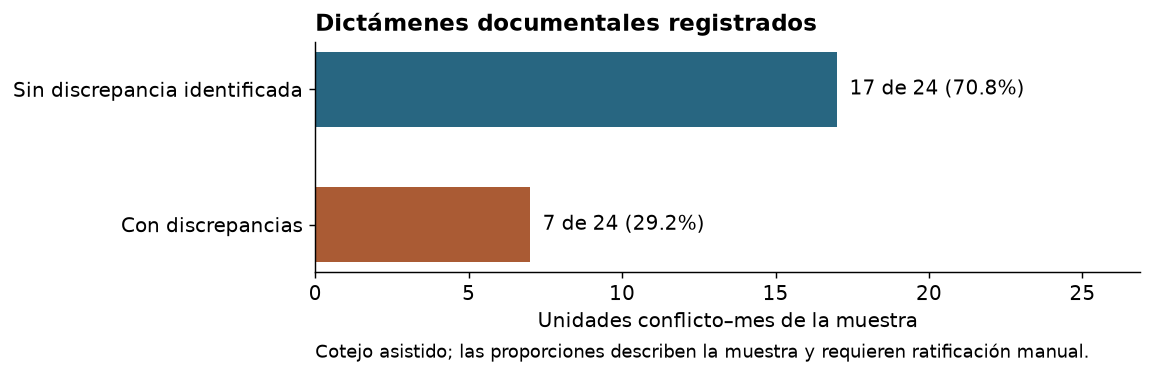

In [14]:
cantidades = [resumen_asistido["Sin discrepancia identificada"], resumen_asistido["Con discrepancias"]]
fig, ax = plt.subplots(figsize=(9, 3.3))
barras = ax.barh(["Sin discrepancia identificada", "Con discrepancias"], cantidades,
                color=["#286681", "#aa5b34"], height=0.55)
ax.invert_yaxis()
ax.bar_label(barras, labels=[f"{n} de {len(muestra)} ({n / len(muestra):.1%})" for n in cantidades], padding=7)
ax.set_xlim(0, len(muestra) * 1.12)
ax.set_xlabel("Unidades conflicto–mes de la muestra")
ax.set_title("Dictámenes documentales registrados", loc="left")
ax.text(0, -0.37, "Cotejo asistido; las proporciones describen la muestra y requieren ratificación manual.",
        transform=ax.transAxes, fontsize=10)
fig.tight_layout()
fig.savefig(RUTA_SALIDAS / "dictamenes_muestra.png", bbox_inches="tight")
plt.show()

### Evidencia de las discrepancias

El caso de Canta conserva a Wari Service en un nombre original compuesto, pero no como
actor independiente en la representación normalizada. En Tumilaca se distinguen el
truncamiento del nombre normalizado de la Secretaría Técnica y la pérdida de «e Ilo»
en otra entidad. Estas diferencias no deben describirse como una ausencia completa
de los nombres en todos los campos.

In [15]:
observaciones = registro[registro.dictamen_reverificado.eq(DISCREPANCIA)][
    ["unidad", "periodo", "referencia", "categorias", "evidencia_reverificada", "paginas_evidencia", "fuente_url"]]
for r in observaciones.to_dict("records"):
    enlace = r["fuente_url"] + "#page=" + r["paginas_evidencia"].split("-")[0]
    display(Markdown(f"**{r['unidad']} · {r['periodo']} · {r['referencia']}.** "
        f"{r['evidencia_reverificada']} "
        f"[Reporte original, pp. {r['paginas_evidencia']}]({enlace})."))
print("Estos señalamientos no se corrigen automáticamente en la base utilizada para los grafos.")

**M01 · 2021-01 · Tía María.** El colectivo de pobladores se divide entre ACT-128 y ACT-044; el segundo conserva un complemento geográfico sin la entidad a la que corresponde. [Reporte original, pp. 35](https://www.defensoria.gob.pe/wp-content/uploads/2021/02/Reporte-Mensual-de-Conflictos-Sociales-N°-203-enero-2021.pdf#page=35).

**M08 · 2022-07 · Canta y derrame de zinc.** Wari Service figura dentro del actor original compuesto, junto con el frente y la población de Canta. No queda como entidad independiente en la representación normalizada; el frente y la población también quedan fusionados. [Reporte original, pp. 66-67](https://www.defensoria.gob.pe/wp-content/uploads/2022/08/Reporte-Mensual-de-Conflictos-Sociales-n.°-221-julio-2022.pdf#page=66).

**M10 · 2023-06 · Tía María.** Se repite la fragmentación del colectivo de pobladores de Cocachacra, Deán Valdivia y Punta Bombón entre ACT-128 y ACT-044. [Reporte original, pp. 41-42](https://www.defensoria.gob.pe/wp-content/uploads/2023/07/Reporte-Mensual-de-Conflictos-Sociales-N°-232-Junio-2023.pdf#page=41).

**M11 · 2023-06 · Tumilaca y Quellaveco.** El campo actor conserva Secretaría Técnica del Comité de Monitoreo; Actor_normalizado de ACT-151 comienza en Seguimiento y Verificación, perdiendo la cabecera de la entidad. [Reporte original, pp. 80-81](https://www.defensoria.gob.pe/wp-content/uploads/2023/07/Reporte-Mensual-de-Conflictos-Sociales-N°-232-Junio-2023.pdf#page=80).

**M18 · 2024-10 · Cuenca del río Ramis.** El colectivo de pobladores de la cuenca Ramis queda dividido entre ACT-129 y el complemento geográfico ACT-145. [Reporte original, pp. 58](https://www.defensoria.gob.pe/wp-content/uploads/2024/11/Reporte-Mensual-de-Conflictos-Sociales-N°-248-Octubre_2024.pdf#page=58).

**M21 · 2025-12 · Tumilaca y Quellaveco.** La fuente conserva organizaciones de la sociedad civil de Mariscal Nieto e Ilo; el campo actor omite e Ilo y recibe ACT-816, frente a ACT-504 en junio de 2023. La misma pérdida de la cabecera de la Secretaría Técnica se observa en Actor_normalizado de ACT-151, pese a que actor la conserva. [Reporte original, pp. 59-60](https://www.defensoria.gob.pe/wp-content/uploads/2026/01/Reporte-de-conflictos-sociales-n.º-262-–-diciembre-2025.pdf#page=59).

**M24 · 2025-12 · Alto Nanay y minería ilegal.** La denominación de CONACCUNAY se divide entre ACT-833 y ACT-832; Chambira y Nanay es parte del nombre y no un actor independiente en el bloque. Las referencias a Amazonas y Rodríguez de Mendoza ya están en el reporte original; se separan de los errores del procesamiento. [Reporte original, pp. 56](https://www.defensoria.gob.pe/wp-content/uploads/2026/01/Reporte-de-conflictos-sociales-n.º-262-–-diciembre-2025.pdf#page=56).

Estos señalamientos no se corrigen automáticamente en la base utilizada para los grafos.


## 5. Trazabilidad de la revisión

El manifiesto registra la base utilizada, las versiones, la semilla y los documentos
consultados. Las fichas y la plantilla permiten completar la revisión manual.
La reproducción de los recuentos no ratifica por sí sola los dictámenes.

In [16]:
manifiesto = {
    "tipo": "Validación documental de la extracción",
    "ejecucion_utc": datetime.now(timezone.utc).isoformat(),
    "archivo_base": RUTA_DATOS.name, "sha256_archivo": sha256_base,
    "sha256_contenido": sha256_contenido,
    "repositorio": REPOSITORIO, "commit_revisado": COMMIT_REFERENCIA,
    "versiones": entorno, "perfil_base": perfil,
    "muestreo": {"semilla": SEMILLA_MUESTRA, "periodos": PERIODOS_MUESTRA,
        "casos_por_periodo": CASOS_POR_PERIODO, "casos_elegibles": elegibles},
    "localizacion": {"paginas_consecutivas": PAGINAS_CONSECUTIVAS,
        "caracteres_descripcion": CARACTERES_DESCRIPCION, "recorte": RECORTE},
    "sha256_csv_referencia_dictamenes": SHA256_ARCHIVO_REFERENCIA,
    "sha256_texto_dictamenes_incorporados": hashlib.sha256(REGISTRO_ASISTIDO_CSV.encode("utf-8")).hexdigest(),
    "sha256_revision_utilizada": huella_archivo(RUTA_SALIDAS / "registro_revision_utilizado.csv"),
    "ratificaciones_manuales": resumen_manual["Con dictamen"],
    "alcance": "Diagnóstico de la muestra; cotejo asistido con ratificación manual separada.",
}
guardar_json("manifiesto_ejecucion_extraccion.json", manifiesto)
archivos = [
    ("muestra_seleccionada.csv", "Unidades seleccionadas y recuentos"),
    ("fichas_para_revision.html", "24 fichas con actores, textos y enlaces oficiales"),
    ("plantilla_revision_manual.csv", "Registro para completar la revisión manual"),
    ("registro_asistido_referencia.csv", "Dictámenes asistidos incorporados"),
    ("registro_revision_utilizado.csv", "Registro efectivamente resumido en esta ejecución"),
    ("resumen_validacion_extraccion.json", "Resultados asistidos y manuales separados"),
    ("manifiesto_ejecucion_extraccion.json", "Versiones, fuentes, huellas y parámetros"),
]
display(pd.DataFrame(archivos, columns=["Archivo generado", "Contenido"]))
display(Markdown(f"**Resultado:** {len(muestra)} unidades; "
    f"{resumen_asistido['Sin discrepancia identificada']} sin discrepancia identificada y "
    f"{resumen_asistido['Con discrepancias']} con discrepancias en el cotejo asistido. "
    f"Ratificación manual: {resumen_manual['Con dictamen']} de {len(muestra)} unidades."))

,Archivo generado,Contenido
0,muestra_seleccionada.csv,Unidades seleccionadas y recuentos
1,fichas_para_revision.html,"24 fichas con actores, textos y enlaces oficiales"
2,plantilla_revision_manual.csv,Registro para completar la revisión manual
3,registro_asistido_referencia.csv,Dictámenes asistidos incorporados
4,registro_revision_utilizado.csv,Registro efectivamente resumido en esta ejecución
5,resumen_validacion_extraccion.json,Resultados asistidos y manuales separados
6,manifiesto_ejecucion_extraccion.json,"Versiones, fuentes, huellas y parámetros"


**Resultado:** 24 unidades; 17 sin discrepancia identificada y 7 con discrepancias en el cotejo asistido. Ratificación manual: 0 de 24 unidades.